# 1 · Physics and maths of a two-wheeled balancing robot

**Tumbller balance course — notebook 1 of 4.**

The Tumbller is an inverted pendulum on wheels. Left alone it falls over in a
fraction of a second; with the motors driving the wheels *under* the falling
body it stands. Before we can talk about controllers we need the plant: a set of
equations that says how tilt and position react to a motor command.

**You should come out knowing:**
- the two coordinates that describe the robot in the plane, and its equations of motion;
- why the reflected rotor inertia of a 30:1 gearmotor is not a detail;
- how a PWM number becomes a torque (and why back-EMF acts as a damper);
- the linear state-space model $\dot s = A s + B u$ and what its eigenvalues say:
  *how fast* the robot falls, and therefore how fast the controller must be.

Everything is built on `tumbller.py`, the small module shared by all four notebooks.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
import tumbller as tb
from tumbller import SERIES, INK, INK2, GRID, tidy
tb.use_style()
p = tb.Params()

## 1.1 · The system and its coordinates

We look at the robot from the side and ignore turning. Two coordinates are enough:

| symbol | meaning | sign |
|---|---|---|
| $x$ | position of the wheel axle along the ground | + forward |
| $\theta$ | tilt of the body from the vertical | + leaning forward |

The wheels roll without slipping, so their rotation is $\varphi = x/r$ — not a
separate coordinate. The motors sit *between* body and wheels: a motor torque
$\tau$ pushes the wheels forward and, by reaction, pushes the body backward.
That reaction is the whole trick, and also the whole difficulty.

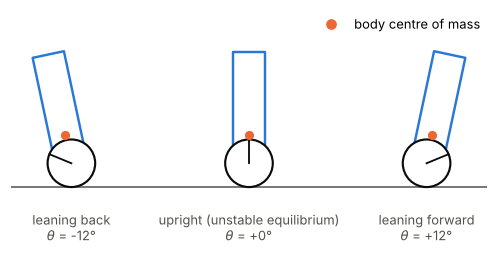

In [2]:
fig, ax = plt.subplots(figsize=(9, 2.6))
for x0, deg, lab in [(-0.25, -12, "leaning back"), (0.0, 0, "upright (unstable equilibrium)"),
                     (0.25, 12, "leaning forward")]:
    tb.draw_robot(ax, p, x0, np.radians(deg))
    ax.text(x0, -0.035, f"{lab}\n$\\theta$ = {deg:+d}°", ha="center", va="top", fontsize=8.5, color=INK2)
ax.axhline(0, color=INK2, lw=1)
ax.set_aspect("equal"); ax.axis("off"); ax.set_ylim(-0.09, 0.22)
ax.plot([], [], "o", color=SERIES[1], label="body centre of mass")
ax.legend(loc="upper left", bbox_to_anchor=(0.62, 1.12))
plt.show()

## 1.2 · Parameters — and how much we trust them

`tb.Params()` holds every number of the model. Each default is marked with its source:

- **[D]** from the datasheets in your Elegoo tutorial folder (GA37-520 motor: 12 V,
  360 rpm no-load, ≥ 5 kg·cm stall torque, 1:30 gearbox);
- **[F]** read from the firmware (5 ms loop, speed loop every 8th tick);
- **[E]** *estimate* — masses, centre-of-mass height, inertias, encoder counts.

The estimates are round, plausible numbers, **not measurements of your robot**.
Notebook 4 shows how to measure each one with kitchen scales, a ruler and a
stopwatch. Until then, treat absolute numbers with suspicion and trends with trust.

In [3]:
print(p.summary())

body   m = 0.800 kg   l = 40 mm   I = 2.00 g m^2
wheels m = 0.070 kg   r = 33.5 mm   I = 400 g cm^2
rotor inertia at wheel  I_r = 0.72 g m^2  (= 0.64 kg equivalent mass!)
motors @ 8.0 V: stall 0.65 Nm, no-load 25.1 rad/s = 0.84 m/s
k_m = 2.56 mNm/count   b_m = 26.0 mNm s/rad
encoder 780 counts/wheel rev   loop 5 ms


One line deserves a second look: the **rotor inertia**. The tiny motor armature
(order $J \approx 4\cdot10^{-7}\,\mathrm{kg\,m^2}$) spins 30 times faster than the
wheel. Kinetic energy goes with speed squared, so seen from the wheel it counts
$30^2 = 900$ times: $I_r = 2\cdot 900\cdot J$. Divided by $r^2$ that is an
*equivalent mass* of the same order as the whole robot. In multibody terms: the
gearbox makes the drivetrain inertia a first-order effect.

## 1.3 · Equations of motion with Lagrange

Positions of the body centre of mass (CoM), with $l$ the distance axle → CoM:

$$x_c = x + l\sin\theta, \qquad z_c = r + l\cos\theta$$

Kinetic energy — wheels translating and rotating, body translating and rotating,
rotors spinning with the *relative* speed between wheel and body:

$$T = \tfrac12 m_w \dot x^2 + \tfrac12 I_w \left(\tfrac{\dot x}{r}\right)^2
    + \tfrac12 m_b\left(\dot x_c^2 + \dot z_c^2\right) + \tfrac12 I_b\dot\theta^2
    + \tfrac12 I_r\left(\tfrac{\dot x}{r} - \dot\theta\right)^2$$

Potential energy $V = m_b\, g\, z_c$. The motor torque does virtual work
$\tau\,(\delta\varphi - \delta\theta)$, which gives the generalised forces
$Q_x = \tau/r$ and $Q_\theta = -\tau$ — there is the reaction on the body.

Let SymPy do the differentiation ($\frac{d}{dt}\frac{\partial L}{\partial \dot q} - \frac{\partial L}{\partial q} = Q$):

In [4]:
import sympy as sp

t = sp.symbols("t")
m_b, m_w, l, r, I_b, I_w, I_r, g = sp.symbols("m_b m_w l r I_b I_w I_r g", positive=True)
tau = sp.symbols("tau", real=True)
x = sp.Function("x")(t)
th = sp.Function("theta")(t)
xd, thd = x.diff(t), th.diff(t)

xc, zc = x + l * sp.sin(th), r + l * sp.cos(th)
half = sp.Rational(1, 2)
T = (half * m_w * xd**2 + half * I_w * (xd / r)**2
     + half * m_b * (xc.diff(t)**2 + zc.diff(t)**2) + half * I_b * thd**2
     + half * I_r * (xd / r - thd)**2)
V = m_b * g * zc
L = T - V

def lagrange(q, Q):
    return sp.simplify(L.diff(q.diff(t)).diff(t) - L.diff(q) - Q)

eq_x = lagrange(x, tau / r)
eq_th = lagrange(th, -tau)

# write as  M(q) q'' = rhs
acc = [x.diff(t, 2), th.diff(t, 2)]
Msym, rhs = sp.linear_eq_to_matrix([eq_x, eq_th], acc)
Msym = sp.simplify(Msym); rhs = sp.simplify(rhs)
display(Msym, rhs)

Matrix([
[(I_r + I_w + r**2*(m_b + m_w))/r**2, -I_r/r + l*m_b*cos(theta(t))],
[       -I_r/r + l*m_b*cos(theta(t)),         I_b + I_r + l**2*m_b]])

Matrix([
[l*m_b*sin(theta(t))*Derivative(theta(t), t)**2 + tau/r],
[                           g*l*m_b*sin(theta(t)) - tau]])

Written out, with $m_{11}, m_{12}, m_{22}$ the entries of the mass matrix above:

$$\boxed{\begin{aligned}
m_{11}\,\ddot x + m_{12}\,\ddot\theta - m_b l \sin\theta\;\dot\theta^2 &= \tau / r\\
m_{12}\,\ddot x + m_{22}\,\ddot\theta - m_b g\, l \sin\theta &= -\tau
\end{aligned}}$$

$$m_{11} = m_b + m_w + \frac{I_w + I_r}{r^2},\qquad
m_{12} = m_b l\cos\theta - \frac{I_r}{r},\qquad
m_{22} = I_b + m_b l^2 + I_r$$

How to read them:
- $m_b g\,l\sin\theta$ is gravity tipping the body — the destabilising term;
- $m_{12}$ is the **coupling**: accelerate the axle forward and the body is rotated
  backward (and vice versa). Without it, wheels could not balance anything;
- the rotor inertia appears in all three entries, and *reduces* the coupling $m_{12}$.

`tb.dynamics()` implements exactly these equations by hand. A check that the
hand-written code and the SymPy derivation agree at a random state:

In [5]:
vals = {m_b: p.m_body, m_w: p.m_wheels, l: p.l, r: p.r, I_b: p.I_body,
        I_w: p.I_wheels, I_r: p.I_rotor, g: tb.G}
s_test = (0.1, 0.3, 0.2, -1.5)            # x, x_dot, theta, theta_dot
u_test = 80.0
tau_test = tb.motor_torque(p, u_test, s_test[1] / p.r - s_test[3])

state = {xd: s_test[1], thd: s_test[3], th: s_test[2], x: s_test[0], tau: tau_test}
M_num = np.array(Msym.subs(vals).subs(state), dtype=float)
rhs_num = np.array(rhs.subs(vals).subs(state), dtype=float).ravel()
acc_sympy = np.linalg.solve(M_num, rhs_num)
acc_module = np.array(tb.dynamics(p, s_test, u_test))[[1, 3]]
print("x'', theta''  from SymPy :", acc_sympy)
print("x'', theta''  from module:", acc_module)
assert np.allclose(acc_sympy, acc_module)

x'', theta''  from SymPy : [-1.5096 36.0195]
x'', theta''  from module: [-1.5096 36.0195]


## 1.4 · From PWM to torque: the motor model

The Arduino does not command torque. It writes a number $u \in [-255, 255]$ to
`analogWrite`, the TB6612 driver chops the battery voltage accordingly, and the
motor answers with a torque that depends on how fast it is already turning:

$$\tau = \underbrace{k_m\,u}_{\text{drive}} \;-\; \underbrace{b_m\,\omega_{rel}}_{\text{back-EMF}},
\qquad \omega_{rel} = \frac{\dot x}{r} - \dot\theta$$

This is the straight torque–speed line of a DC motor (winding inductance
neglected — its time constant is well below our 5 ms loop). Both constants follow
from two datasheet numbers scaled to battery voltage:

- stall torque (both motors, full PWM) $\;\tau_{stall} = k_m \cdot 255$
- no-load speed $\;\omega_0 = \tau_{stall} / b_m$

Two consequences worth remembering:
1. **Back-EMF is a viscous damper** between wheel and body. It is there even at
   $u = 0$ (the driver short-brakes the motor), and it is strong.
2. **Battery voltage is a gain.** Everything the controller outputs is multiplied
   by $V_{batt}$. A robot tuned at 8.4 V has about 15 % less loop gain at 7.2 V.

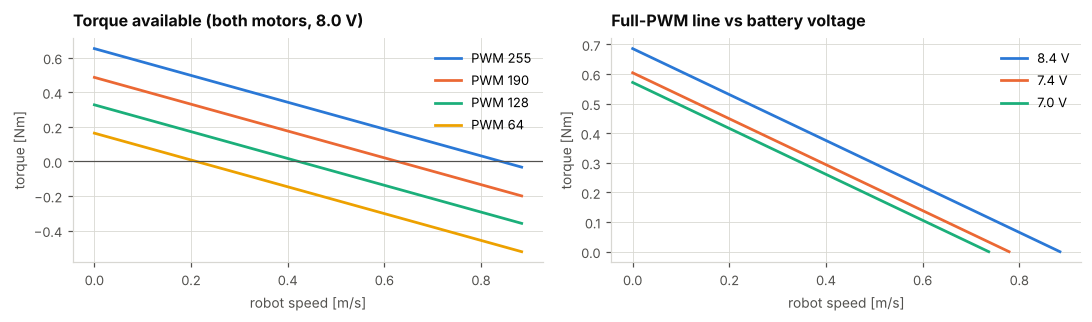

gravity torque at 10 deg tilt :  54.5 mNm
stall torque of the motors    :   653 mNm
top speed (no load)           :  0.84 m/s


In [6]:
w = np.linspace(0, p.w0 * 1.05, 50)
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for u in (255, 190, 128, 64):
    axs[0].plot(w * p.r, p.k_m * u - p.b_m * w, label=f"PWM {u}")
axs[0].axhline(0, color=INK2, lw=0.8)
axs[0].legend()
tidy(axs[0], f"Torque available (both motors, {p.v_batt:.1f} V)", "robot speed [m/s]", "torque [Nm]")

for v in (8.4, 7.4, 7.0):
    q = p.with_(v_batt=v)
    axs[1].plot([0, q.w0 * q.r], [q.stall_total, 0], label=f"{v:.1f} V")
axs[1].legend()
tidy(axs[1], "Full-PWM line vs battery voltage", "robot speed [m/s]", "torque [Nm]")
plt.tight_layout(); plt.show()

grav = p.m_body * tb.G * p.l
print(f"gravity torque at 10 deg tilt : {grav*np.sin(np.radians(10))*1e3:5.1f} mNm")
print(f"stall torque of the motors    : {p.stall_total*1e3:5.0f} mNm")
print(f"top speed (no load)           : {p.w0*p.r:5.2f} m/s")

Torque is plentiful: the motors can hold many times the gravity torque. What runs
out is **speed**. To catch a falling body the wheels must *accelerate*, and near
top speed there is no torque left to do so. That is why a balancing robot that is
pushed too hard, or driven too fast, falls — we will see it in notebook 3.

## 1.5 · Linearisation and the state-space model

Near upright, $\sin\theta \approx \theta$, $\cos\theta \approx 1$, and
$\dot\theta^2 \approx 0$. With the state vector

$$s = \begin{bmatrix} x & \dot x & \theta & \dot\theta \end{bmatrix}^T$$

the model becomes $\dot s = A\,s + B\,u$, with $u$ in PWM counts.
`tb.linearize(p)` builds $A$ and $B$ from the equations above (motor included):

In [7]:
A, B = tb.linearize(p)
print("A =\n", A)
print("\nB =", B.ravel())

# the linear model must match the nonlinear one for small states
s_small = np.array([0.0, 0.05, 0.02, 0.1])
print("\nnonlinear:", np.array(tb.dynamics(p, s_small, 10.0)))
print("linear   :", A @ s_small + B[:, 0] * 10.0)

A =
 [[  0.       1.       0.       0.    ]
 [  0.     -16.5841  -0.5427   0.5556]
 [  0.       0.       0.       1.    ]
 [  0.     237.5545  79.9055  -7.9581]]

B = [ 0.      0.0548  0.     -0.7844]

nonlinear: [ 0.05   -0.2369  0.1     4.8358]
linear   : [ 0.05   -0.2369  0.1     4.8364]


Read the signs in $B$: a positive command accelerates the axle forward
($B_2 > 0$) and rotates the body **backward** ($B_4 < 0$). To stop a forward
lean ($\theta > 0$) we therefore need $u > 0$: *drive towards the side you are
falling to*.

### Eigenvalues: how fast does it fall?

The eigenvalues of $A$ are the natural motions of the uncontrolled robot:

In [8]:
ev = np.sort(np.linalg.eigvals(A).real)
lam = ev[-1]
for e, what in zip(ev, ["fast, stable: wheel/rotor speed dying out against back-EMF",
                        "stable: body swinging 'down' against the motor damping",
                        "zero: position x has no restoring force",
                        "UNSTABLE: the fall"]):
    print(f"  {e:8.2f} 1/s   {what}")
print(f"\nunstable pole  lambda = {lam:.2f} 1/s")
print(f"tilt doubles every   ln2/lambda = {np.log(2)/lam*1e3:.0f} ms")
print(f"compare: loop period {p.dt*1e3:.0f} ms  ->  {np.log(2)/lam/p.dt:.0f} control ticks per doubling")
print(f"rigid pendulum with locked wheels would give sqrt(m g l / I) = "
      f"{np.sqrt(p.m_body*tb.G*p.l/(p.I_body+p.m_body*p.l**2)):.2f} 1/s")

    -25.84 1/s   fast, stable: wheel/rotor speed dying out against back-EMF
     -6.18 1/s   stable: body swinging 'down' against the motor damping
      0.00 1/s   zero: position x has no restoring force
      7.49 1/s   UNSTABLE: the fall

unstable pole  lambda = 7.49 1/s
tilt doubles every   ln2/lambda = 93 ms
compare: loop period 5 ms  ->  19 control ticks per doubling
rigid pendulum with locked wheels would give sqrt(m g l / I) = 9.78 1/s


One positive eigenvalue: any small tilt grows like $e^{\lambda t}$. With the
default numbers the tilt doubles roughly every 90 ms. A 5 ms control loop sees
that doubling spread over many ticks — comfortable. A 40 ms loop would not.

How do the design parameters move that pole?

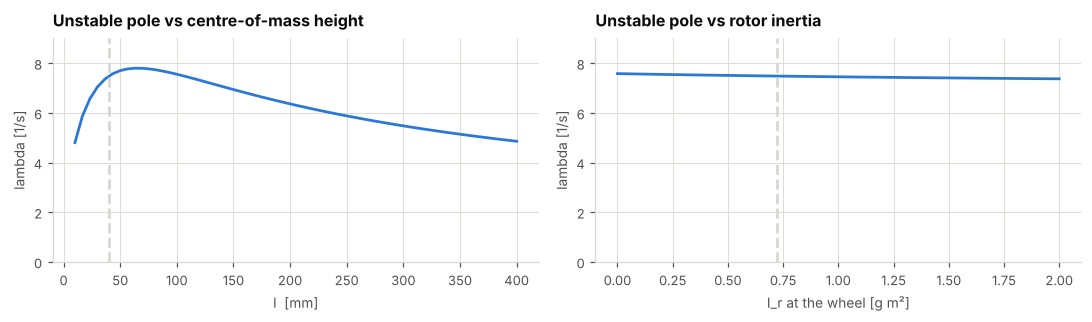

In [9]:
def unstable_pole(q):
    return np.max(np.linalg.eigvals(tb.linearize(q)[0]).real)

ls = np.linspace(0.01, 0.40, 60)
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
# keep the body's own radius of gyration fixed while moving the CoM
axs[0].plot(ls * 1e3, [unstable_pole(p.with_(l=v)) for v in ls])
axs[0].axvline(p.l * 1e3, color=GRID, ls="--")
axs[0].set_ylim(0, 9)
tidy(axs[0], "Unstable pole vs centre-of-mass height", "l  [mm]", "lambda [1/s]")

Irs = np.linspace(0, 2e-3, 40)
axs[1].plot(Irs * 1e3, [unstable_pole(p.with_(I_rotor=v)) for v in Irs])
axs[1].axvline(p.I_rotor * 1e3, color=GRID, ls="--")
axs[1].set_ylim(0, 9)
tidy(axs[1], "Unstable pole vs rotor inertia", "I_r at the wheel [g m²]", "lambda [1/s]")
plt.tight_layout(); plt.show()

Left: the curve rises, peaks and then falls — a **tall** robot falls *slower*,
just as a broomstick is easier to balance on your hand than a pencil. Stacking
the battery high is a legitimate design choice. Right: the rotor inertia barely
moves the fall rate — its influence shows up elsewhere (how quickly the wheels
can be accelerated).

## 1.6 · Watching it fall

Motors unpowered ($u = 0$), released 1° off vertical. Nonlinear simulation
(RK4 on `tb.dynamics`) against the linear prediction $e^{At}s_0$:

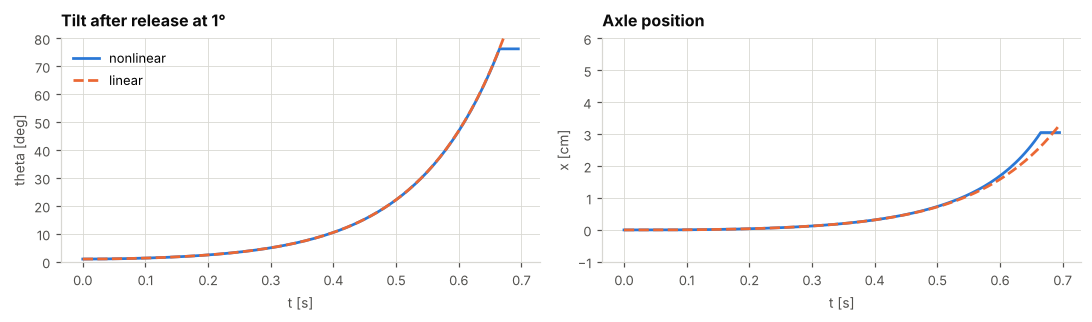

1 deg -> 20 deg in 490 ms


In [10]:
from scipy.linalg import expm

fall = tb.simulate(p, controller="none", theta0_deg=1.0, t_end=0.7,
                   sensors=tb.SensorModel(ideal=True))
s0 = np.array([0, 0, np.radians(1.0), 0])
lin = np.array([expm(A * tt) @ s0 for tt in fall.t])

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(fall.t, fall.theta_deg, label="nonlinear")
axs[0].plot(fall.t, np.degrees(lin[:, 2]), ls="--", label="linear")
axs[0].set_ylim(0, 80); axs[0].legend()
tidy(axs[0], "Tilt after release at 1°", "t [s]", "theta [deg]")
axs[1].plot(fall.t, fall.x * 100, label="nonlinear")
axs[1].plot(fall.t, lin[:, 0] * 100, ls="--", label="linear")
axs[1].set_ylim(-1, 6)
tidy(axs[1], "Axle position", "t [s]", "x [cm]")
plt.tight_layout(); plt.show()

t20 = fall.t[np.argmax(fall.theta_deg > 20)]
print(f"1 deg -> 20 deg in {t20*1e3:.0f} ms")

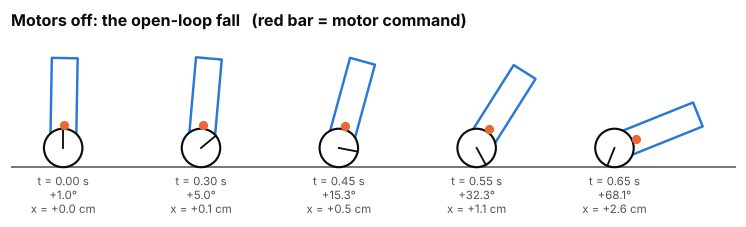

In [11]:
tb.filmstrip(fall, [0.0, 0.3, 0.45, 0.55, 0.65], spread=0.24, title="Motors off: the open-loop fall")
plt.show()

Run the next cell for the animation (its output is not stored in the file, to keep the notebook small):

In [ ]:
HTML(tb.animate(fall, every=4, window=0.3, title="Motors off: the open-loop fall").to_jshtml())

The axle rolls **forward** while the body falls forward: the falling body drags
the wheels along through the motor damping. The linear model tracks the true
tilt closely over the whole range in which the firmware operates (it cuts the
motors beyond ±22°), so it is a fair basis for controller design. We use it in
notebook 2.

## 1.7 · Take-aways

- Two coordinates ($x$, $\theta$), two coupled equations; the coupling term
  $m_{12}$ is what lets wheels steer the tilt.
- Motor command → torque is a line with a strong built-in damper (back-EMF);
  battery voltage scales the whole thing.
- The robot has one unstable eigenvalue of roughly 7–8 1/s: tilt doubles in
  about 90 ms. The controller must act well inside that time.
- Torque is not the limit, wheel speed is.

## Exercises

1. Set `p2 = p.with_(I_rotor=0)` and compare `tb.linearize(p2)` with the default.
   Which entries of $A$ and $B$ change most? What happens to the fast stable pole?
2. Double the body mass with the CoM unchanged. Does the robot fall faster?
   Explain with the rigid-pendulum formula $\sqrt{m g l / I}$.
3. From the equations in 1.3, derive the horizontal acceleration $\ddot x$ needed
   to hold a constant tilt $\theta_0$ (set $\ddot\theta = \dot\theta = 0$).
   This "lean to accelerate" relation is the basis of the speed loop.
4. Change `v_batt` from 8.4 to 7.0. By what factor do `k_m` and `b_m` change, and why
   does only one of them change?